Loaded: /content/WhatsApp Audio 2026-11-05 at 23.02.20 (1).mpeg
Sampling rate : 44100 Hz
Samples (N)   : 1169280
Duration      : 26.514 s


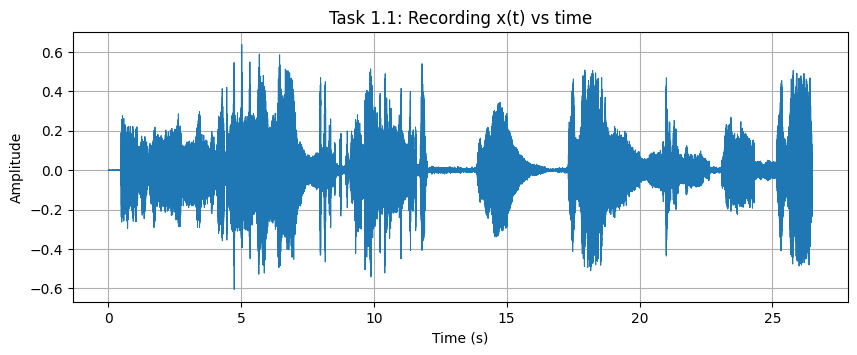

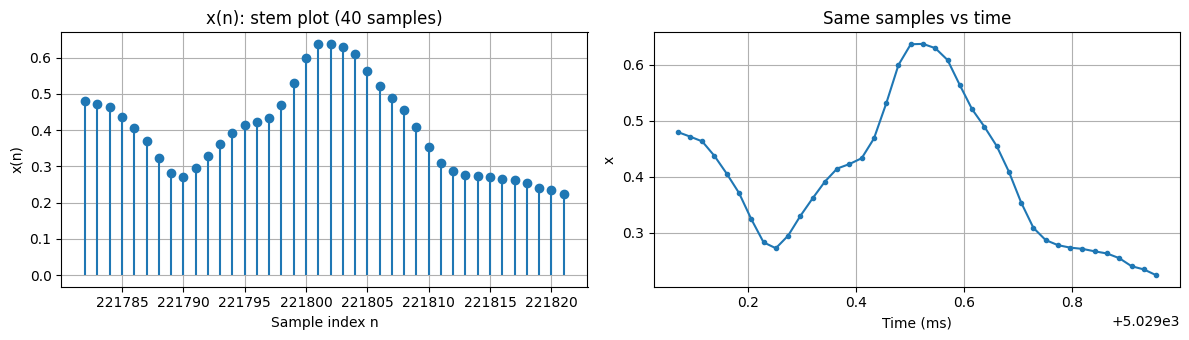

Time between samples T = 1/fs = 0.0227 ms


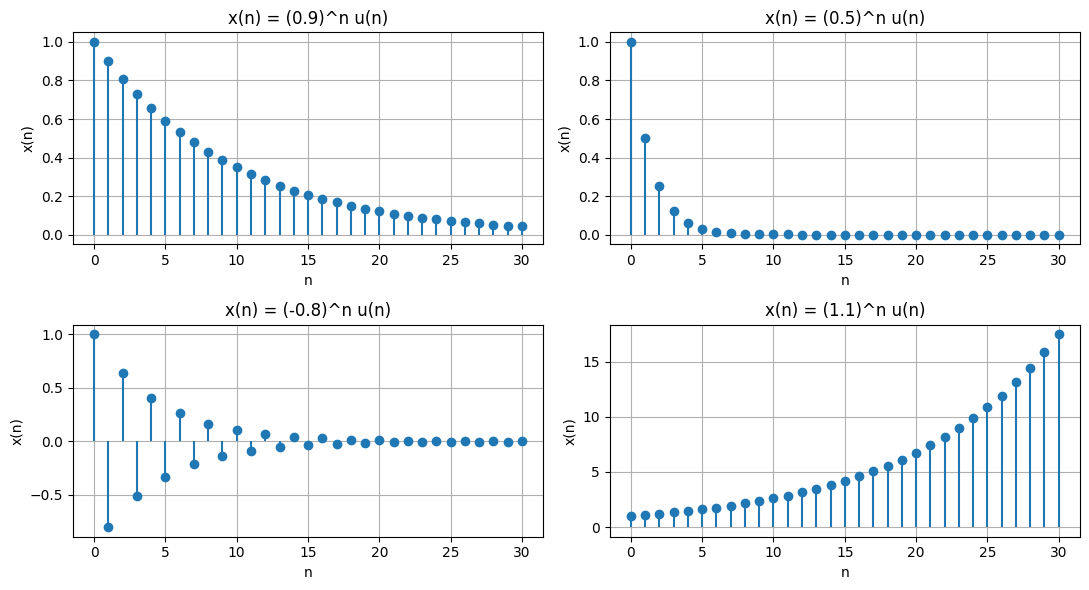

a = 1.1 -> x(30) = 17.44940226888645

--- Checkpoint 1 ---
Sampling rate = 44100 Hz
Duration      = 26.51 s  (1169280 samples)

--- Q1 ---
One minute mono = fs x 60 = 2,646,000 numbers
  (for reference) at 44100 Hz: 2,646,000 numbers
  (for reference) at 48000 Hz: 2,880,000 numbers


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True})

# ---------- PASTE YOUR PATH HERE ----------
path = "/content/WhatsApp Audio 2026-11-05 at 23.02.20 (1).mpeg"
# ------------------------------------------

# Task 1.1: load and plot
x, fs = librosa.load(path, sr=None, mono=True)   # native sampling rate, mono
print("Loaded:", path)

N = len(x)
duration = N / fs
t = np.arange(N) / fs

print(f"Sampling rate : {fs} Hz")
print(f"Samples (N)   : {N}")
print(f"Duration      : {duration:.3f} s")

plt.plot(t, x, lw=0.7)
plt.title("Task 1.1: Recording x(t) vs time")
plt.xlabel("Time (s)"); plt.ylabel("Amplitude")
plt.show()

# Task 1.2: stem plot of 40 samples around the loudest point
center = int(np.argmax(np.abs(x)))
start = max(0, center - 20)
n = np.arange(start, start + 40)
seg = x[start:start + 40]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].stem(n, seg, basefmt=" ")
ax[0].set(title="x(n): stem plot (40 samples)", xlabel="Sample index n", ylabel="x(n)")
ax[1].plot(n/fs*1000, seg, "o-", ms=3)
ax[1].set(title="Same samples vs time", xlabel="Time (ms)", ylabel="x")
plt.tight_layout(); plt.show()

print(f"Time between samples T = 1/fs = {1000/fs:.4f} ms")

# Task 1.3: exponential sequences
n = np.arange(0, 31)
values = [0.9, 0.5, -0.8, 1.1]

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, a in zip(axes.ravel(), values):
    ax.stem(n, a**n, basefmt=" ")
    ax.set(title=f"x(n) = ({a})^n u(n)", xlabel="n", ylabel="x(n)")
plt.tight_layout(); plt.show()

print("a = 1.1 -> x(30) =", 1.1**30)

# Checkpoint 1
print("\n--- Checkpoint 1 ---")
print(f"Sampling rate = {fs} Hz")
print(f"Duration      = {duration:.2f} s  ({N} samples)")

# Q1
print("\n--- Q1 ---")
print(f"One minute mono = fs x 60 = {fs*60:,} numbers")
for rate in (44100, 48000):
    print(f"  (for reference) at {rate} Hz: {rate*60:,} numbers")

 Q1. Sampling rate of the recording; numbers needed for one minute in mono

**Answer 1.** My recording's sampling rate is printed above (typically **44 100 Hz  for phones).
Mono needs one number per sample, so one minute needs **fs × 60** numbers — 44 100 × 60 = **2 646 000**
. Stereo would need twice as many.

### Q2. Why a stem plot rather than a continuous line for x(n)?
**Answer 2.** x(n) is a *discrete-time* signal: it is defined only at integer values of n and has **no value between samples**.
A continuous line wrongly suggests the signal exists (and is interpolated) between samples. A stem plot shows each
sample as an isolated value at its own index, which is the true nature of the sequence. (A line is acceptable only
for a very dense recording, where it approximates the underlying analog x(t).)

### Q3. For a = 1.1 the exponential grows. Which system property would it violate as an impulse response?
**Answer 3.** It would violate **BIBO (bounded-input bounded-output) stability**. A LTI system is stable if and only if
its impulse response is absolutely summable:

 Σ|h(n)| < ∞.

For h(n) = 1.1ⁿ u(n),

Σ 1.1ⁿ = ∞ (the terms grow without bound), so a bounded input ( a unit step) gives an unbounded output.
The system is still **causal**

(h(n) = 0 for n < 0) and LTI, but **unstable**. For |a| < 1 the sum converges to 1/(1−a), so it is stable.



